# 06 · NLP: robustez, atajos, incertidumbre, explicabilidad y equidad (contexto de reclutamiento)

El análisis se ejecuta sobre el **mejor modelo de cada familia**. Para no depender de GPU, el código se
demuestra con TF-IDF + LR; cualquier modelo de `project.nlp_pipeline.registry()` se puede sustituir en
`MODEL`. Todo ajuste (umbral, temperatura, cuantil conforme) usa **solo validación**.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from project.calibration import (conformal_report, conformal_sets, conformal_threshold, coverage_for_accuracy,
                                 risk_coverage_curve)
from project.config import CFG, report_dirs, set_global_seed
from project.fairness import age_swap, counterfactual_flip_rate, fairness_report, gender_swap
from project.nlp_pipeline import classification_metrics, registry
from project.robustness_text import INVARIANCE_TESTS, invariance_report, mask_tokens
from project.stats import bootstrap_ci, fmt_ci, mcnemar_exact

warnings.filterwarnings("ignore")
set_global_seed(CFG.seed)
ROOT = Path("..").resolve()
REAL = (ROOT / "data/processed/nlp_splits.csv").exists()
df = pd.read_csv(ROOT / ("data/processed/nlp_splits.csv" if REAL else "data/processed/demo_nlp_splits.csv"))
TAB, FIG = report_dirs(ROOT, REAL)
tr, va, te = (df[df.split == s] for s in ("train", "val", "test"))
classes = np.unique(df.label)
MODEL = "TF-IDF + LR"
m = registry()[MODEL].fit(tr.text.tolist(), tr.label.to_numpy(), va.text.tolist(), va.label.to_numpy(), 0)
proba = lambda X: m.predict_proba(list(X))
predict = lambda X: classes[proba(X).argmax(1)]
P_te = proba(te.text); base = classification_metrics(te.label.to_numpy(), P_te, classes)
print("Modo:", "REAL" if REAL else "DEMO — cifras no reportables", f"| {MODEL}: F1 macro test = {base['f1_macro']:.3f}")

Modo: REAL | TF-IDF + LR: F1 macro test = 0.595


## 1. Pruebas de invarianza y direccionalidad (CheckList)

**Invarianza (INV):** cambiar mayúsculas, introducir errores tipográficos, usar sinónimos o cambiar
nombres propios no debería cambiar la predicción. Se reporta la tasa de fallo con IC.
**Direccionalidad (DIR):** añadir evidencia de la clase debería aumentar su probabilidad.

In [2]:
tests = dict(INVARIANCE_TESTS)
tests["nombres"] = lambda t: t.replace("James", "Priya").replace("Mary", "Wei")
tests["retrotraduccion*"] = lambda t: t   # *requiere un traductor (p. ej. MarianMT en→es→en); se deja declarado
inv = invariance_report(predict, te.text.tolist(), tests)
cis = {}
for k, f in tests.items():
    flips = (predict([f(t) for t in te.text]) != predict(te.text)).astype(float)
    cis[k] = fmt_ci(*bootstrap_ci(flips))
print("Tasa de cambio de predicción (INV) [IC 95 %]:", cis)
# DIR: añadir la palabra más discriminativa de la clase verdadera
vec, clf = m.m_.steps[0][1], m.m_.steps[1][1]
vocab = np.array(vec.get_feature_names_out())
top_word = {c: vocab[np.argmax(clf.coef_[i] if clf.coef_.shape[0] > 1 else (clf.coef_[0] if i else -clf.coef_[0]))] for i, c in enumerate(classes)}
ok = []
for t, y in zip(te.text, te.label):
    j = list(classes).index(y)
    ok.append(proba([t + " " + top_word[y]])[0, j] >= proba([t])[0, j])
print("DIR (añadir evidencia aumenta p(clase)):", fmt_ci(*bootstrap_ci(np.array(ok, float))), "| palabras:", top_word)

Tasa de cambio de predicción (INV) [IC 95 %]: {'mayusculas': '0.000 [0.000, 0.000]', 'typos_5pct': '0.017 [0.006, 0.031]', 'sinonimos': '0.020 [0.006, 0.034]', 'nombres': '0.000 [0.000, 0.000]', 'retrotraduccion*': '0.000 [0.000, 0.000]'}


DIR (añadir evidencia aumenta p(clase)): 0.997 [0.992, 1.000] | palabras: {'ACCOUNTANT': 'accountant', 'ADVOCATE': 'advocate', 'AGRICULTURE': 'agriculture', 'APPAREL': 'apparel', 'ARTS': 'arts', 'AUTOMOBILE': 'automobile', 'AVIATION': 'aviation', 'BANKING': 'banking', 'BPO': 'bpo', 'BUSINESS-DEVELOPMENT': 'business development', 'CHEF': 'chef', 'CONSTRUCTION': 'construction', 'CONSULTANT': 'consultant', 'DESIGNER': 'designer', 'DIGITAL-MEDIA': 'digital', 'ENGINEERING': 'engineering', 'FINANCE': 'finance', 'FITNESS': 'fitness', 'HEALTHCARE': 'healthcare', 'HR': 'hr', 'INFORMATION-TECHNOLOGY': 'information technology', 'PUBLIC-RELATIONS': 'public relations', 'SALES': 'sales', 'TEACHER': 'teacher'}


## 2. Ablación de atajos

Se enmascaran las palabras o plantillas sospechosas detectadas en el notebook 04 (log-odds con patrón
de plantilla, código, fecha o nombre) y se mide la caída de F1. **Un modelo cuya métrica colapsa
aprendió el atajo, no la tarea.** El modelo se re-entrena también sin el atajo para separar la
dependencia del modelo de la del dato.

In [3]:
lo_path = TAB / "nlp_log_odds.csv"
sus = set(pd.read_csv(lo_path).query("sospecha_atajo").palabra) if lo_path.exists() else set()
sus |= {w for w in vocab if w.startswith("ref_") and " " not in w}           # en el corpus demo, el atajo es 'ref_<clase>'
print("Tokens enmascarados:", sorted(sus)[:20])
te_m = [mask_tokens(t, sus) for t in te.text]
f_mask = classification_metrics(te.label.to_numpy(), proba(te_m), classes)["f1_macro"]
m2 = registry()[MODEL].fit([mask_tokens(t, sus) for t in tr.text], tr.label.to_numpy(), [mask_tokens(t, sus) for t in va.text], va.label.to_numpy(), 0)
f_retrain = classification_metrics(te.label.to_numpy(), m2.predict_proba(te_m), classes)["f1_macro"]
print(f"F1 test: original {base['f1_macro']:.3f} | test enmascarado {f_mask:.3f} | re-entrenado sin atajo {f_retrain:.3f}")
print("p McNemar (original vs enmascarado):", mcnemar_exact(te.label.to_numpy(), predict(te.text), classes[proba(te_m).argmax(1)]))

Tokens enmascarados: ['3d']


TypeError: expected string or bytes-like object, got 'float'

## 3. Fuera de distribución y ruido de etiquetas

* **OOD:** si hay otra fuente o periodo (columna temporal o de origen), se evalúa allí. En el modo demo
  se simula con deriva de vocabulario (`drift_sim.drift_vocab`, severidad 0.5).
* **Ruido:** se re-evalúa tras excluir los ejemplos de test marcados como sospechosos por *confident
  learning* (notebook 04). ¿Cambia el ranking?

In [4]:
from project.drift_sim import drift_vocab
rng = np.random.default_rng(0)
ood = [drift_vocab(t, 0.5, rng) for t in te.text]
print("F1 en OOD simulado:", round(classification_metrics(te.label.to_numpy(), proba(ood), classes)["f1_macro"], 3))
sp = TAB / "nlp_sospechosos_para_revision.csv"
if sp.exists():
    s_idx = set(pd.read_csv(sp, index_col=0).index)
    keep = ~te.index.isin(s_idx)
    print("F1 test sin sospechosos:", round(classification_metrics(te.label[keep].to_numpy(), P_te[keep], classes)["f1_macro"], 3),
          f"(excluidos {(~keep).sum()})")

F1 en OOD simulado: 0.597
F1 test sin sospechosos: 0.603 (excluidos 8)


## 4. Incertidumbre: predicción conforme y clasificación selectiva

Se usa *split conformal* (LAC) calibrado en validación con α = 0.1, y se verifica empíricamente la
cobertura en test. Con la curva riesgo–cobertura se calcula qué porcentaje de casos habría que derivar
a revisión humana para alcanzar una exactitud objetivo.

Conforme α=0.1: cobertura empírica = 0.912 (objetivo ≥ 0.90), tamaño medio = 3.64
Exactitud objetivo 95%: cobertura automática 4.2% → revisión humana 95.8%
Exactitud objetivo 99%: cobertura automática 4.2% → revisión humana 95.8%


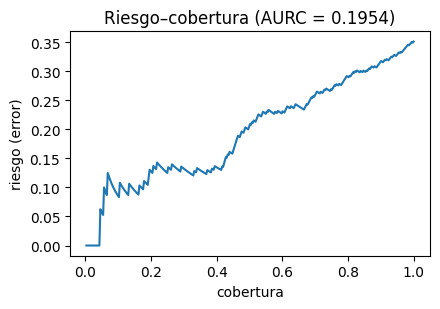

In [5]:
P_va = proba(va.text); yv = np.searchsorted(classes, va.label); yt = np.searchsorted(classes, te.label)
q = conformal_threshold(P_va, yv, alpha=0.1)
rep = conformal_report(conformal_sets(P_te, q), yt)
print(f"Conforme α=0.1: cobertura empírica = {rep['coverage']:.3f} (objetivo ≥ 0.90), tamaño medio = {rep['avg_set_size']:.2f}")
rc = risk_coverage_curve(P_te.max(1), P_te.argmax(1) == yt)
for target in (0.95, 0.99):
    cov = coverage_for_accuracy(P_te.max(1), P_te.argmax(1) == yt, target)
    print(f"Exactitud objetivo {target:.0%}: cobertura automática {cov:.1%} → revisión humana {1 - cov:.1%}")
plt.figure(figsize=(4.5, 3.2)); plt.plot(rc["coverage"], rc["risk"]); plt.xlabel("cobertura"); plt.ylabel("riesgo (error)")
plt.title(f"Riesgo–cobertura (AURC = {rc['aurc']:.4f})"); plt.tight_layout()

## 5. Explicabilidad y fidelidad

* Lineales y XGBoost: coeficientes o SHAP (`shap.TreeExplainer` para XGBoost). Transformer: gradientes
  integrados (`captum`). LIME como contraste.
* **Fidelidad (deletion):** se eliminan los k tokens más importantes según la explicación y se mide la
  caída de p(clase predicha), comparada con eliminar k tokens al azar. Una explicación fiel produce una
  caída mayor.

In [6]:
coef = clf.coef_ if clf.coef_.shape[0] > 1 else np.vstack([-clf.coef_[0], clf.coef_[0]])
w_idx = {w: i for i, w in enumerate(vocab)}
def explain(t, c):
    toks = t.split(); return sorted(toks, key=lambda w: -coef[c, w_idx.get(w.lower(), 0)] if w.lower() in w_idx else 0)
drops = {"explicación": [], "azar": []}
for t in te.text.sample(min(200, len(te)), random_state=0):
    p0 = proba([t])[0]; c = p0.argmax(); toks = t.split()
    if len(toks) < 6: continue
    top = set(explain(t, c)[:3])
    rnd = set(rng.choice(toks, 3, replace=False))
    drops["explicación"].append(p0[c] - proba([" ".join(w for w in toks if w not in top)])[0, c])
    drops["azar"].append(p0[c] - proba([" ".join(w for w in toks if w not in rnd)])[0, c])
print({k: fmt_ci(*bootstrap_ci(np.array(v))) for k, v in drops.items()}, "(caída de p(clase) al borrar 3 tokens)")
top_feats = pd.DataFrame({c: vocab[np.argsort(-coef[i])[:10]] for i, c in enumerate(classes)})
top_feats

{'explicación': '0.058 [0.052, 0.064]', 'azar': '0.002 [0.001, 0.004]'} (caída de p(clase) al borrar 3 tokens)


,ACCOUNTANT,ADVOCATE,AGRICULTURE,APPAREL,ARTS,AUTOMOBILE,AVIATION,BANKING,BPO,BUSINESS-DEVELOPMENT,...,DIGITAL-MEDIA,ENGINEERING,FINANCE,FITNESS,HEALTHCARE,HR,INFORMATION-TECHNOLOGY,PUBLIC-RELATIONS,SALES,TEACHER
0,accountant,advocate,agriculture,apparel,arts,automobile,aviation,banking,bpo,business development,...,digital,engineering,finance,fitness,healthcare,hr,information technology,public relations,sales,teacher
1,accounting,advocate summary,agricultural,merchandising,students,police,aircraft,bank,metrics,development manager,...,media,engineering manager,finance manager,exercise,medical,employee,technology,public,sales associate,classroom
2,ledger,child,natural resources,store,language arts,claims,flight,loan,call,sales,...,digital media,engineer,financial,fitness instructor,patient,human,network,relations,experience sales,students
3,entries,patient,farmers,fashion,arts teacher,aaa,navy,teller,google maps,development,...,content,electrical,accounting,instructor,care,human resources,technology specialist,press,customers,teaching
4,general ledger,care,molecular,inventory,teacher,call center,maintenance,financial,customer services,business,...,digital marketing,engineering intern,experience finance,trainer,clinical,benefits,infrastructure,media,merchandise,learning
5,accounts,families,research,sales,parents,auto,repair,credit,client,marketing,...,analytics,experience engineering,forecasting,group fitness,health,employee relations,hardware,press releases,store,lesson
6,financial,advocacy,research assistant,product,summer,ca,safety,loans,sr,territory,...,marketing,mechanical,finance director,members,patients,compensation,security,releases,associate,children
7,reconciliations,case,natural,merchandise,teachers,call,naval,branch,commerce,experience business,...,social media,engineering technician,cash,personal trainer,physicians,payroll,information,event,associate summary,curriculum
8,financial statements,health,soil,production,school,processed,logistics,mortgage,hiring,opportunities,...,strategy,manufacturing,audit,personal training,nursing,recruitment,sql,pr,current sales,teacher summary
9,accountant summary,court,conservation,retail,art,inquiries,military,investment,india,market,...,social,electronics,reporting,wellness,health care,hris,server,events,sales summary,student


### Taxonomía de errores (anotación manual)

Para cada modelo clave se exportan ≥ 50 errores a `nlp_errores_para_anotar.csv`. Dos anotadores los
clasifican con categorías definidas **a priori** (ambigüedad, etiqueta dudosa, negación, sarcasmo,
dominio, longitud, otro) y se reporta κ de Cohen (`sklearn.metrics.cohen_kappa_score`).

In [7]:
err = te[predict(te.text) != te.label].assign(pred=lambda d: predict(d.text))
err.head(max(50, len(err)))[["text", "label", "pred"]].assign(categoria_A="", categoria_B="").to_csv(TAB / "nlp_errores_para_anotar.csv")
ann_f = TAB / "nlp_errores_anotados.csv"
if ann_f.exists():
    from sklearn.metrics import cohen_kappa_score
    a = pd.read_csv(ann_f); print("κ de Cohen =", round(cohen_kappa_score(a.categoria_A, a.categoria_B), 3)); print(a.categoria_A.value_counts())
else:
    print(f"{len(err)} errores exportados para anotación manual.")

124 errores exportados para anotación manual.


## 6. Equidad y riesgo (selección de personal)

**Pruebas contrafactuales.** Se intercambian términos asociados a género y a edad y se mide el cambio en
la probabilidad de la clase favorable. Lo deseable es un cambio ≈ 0.

**Métricas por subgrupo.** Solo se calculan cuando existe un atributo o un proxy justificable, como
pronombres o términos de género en el texto. Se reportan paridad demográfica, igualdad de
oportunidades, probabilidades equalizadas y razón de impacto dispar (regla 4/5), con IC. *Los proxies
inferidos del texto son imperfectos y su uso se documenta en la model card.*

In [8]:
FAV = classes[0]   # declarar en la model card qué clase es la decisión favorable (p. ej. «avanza a entrevista»)
fav_idx = list(classes).index(FAV)
cf_g = counterfactual_flip_rate(proba, te.text.tolist(), gender_swap, fav_idx)
cf_a = counterfactual_flip_rate(proba, te.text.tolist(), age_swap, fav_idx)
print("Contrafactual de género:", cf_g); print("Contrafactual de edad:", cf_a)
# Prueba sintética de sensibilidad: insertar un término de género en textos neutros
ins = te.text.sample(min(200, len(te)), random_state=1).tolist()
d_gender = proba(["she " + t for t in ins])[:, fav_idx] - proba(["he " + t for t in ins])[:, fav_idx]
print("Δp(favorable) 'she' − 'he' (inserción):", fmt_ci(*bootstrap_ci(d_gender)))
from project.text_data import tokenize
fem = {"she", "her", "hers", "woman", "female", "mrs", "ms", "ella", "mujer", "señora"}
mas = {"he", "him", "his", "man", "male", "mr", "él", "hombre", "señor"}
grp = np.array(["fem" if set(tokenize(t)) & fem and not set(tokenize(t)) & mas else
                "mas" if set(tokenize(t)) & mas and not set(tokenize(t)) & fem else "sin_proxy" for t in te.text])
if (pd.Series(grp).value_counts().drop("sin_proxy", errors="ignore") >= 30).sum() >= 2:
    sel = grp != "sin_proxy"
    fr = fairness_report((te.label.to_numpy() == FAV)[sel].astype(int), (predict(te.text) == FAV)[sel].astype(int), grp[sel])
    print(fr["rates"].round(3)); print({k: tuple(round(x, 3) for x in v) for k, v in fr["metrics"].items()}, "| regla 4/5:", fr["four_fifths_ok"])
else:
    print("Subgrupos por proxy de género insuficientes (< 30 por grupo): no se reportan métricas de subgrupo; "
          "se documenta la limitación y se recomiendan atributos auto-declarados con consentimiento.")

Contrafactual de género: {'n_changed': 116, 'mean_abs_delta': 0.00024258930667229545, 'ci_low': 0.00017614646881727338, 'ci_high': 0.0003217651529749072, 'max_abs_delta': 0.002681801187625066, 'flip_rate': 0.0}
Contrafactual de edad: {'n_changed': 3, 'mean_abs_delta': 3.337766435256191e-05, 'ci_low': 1.840990692947124e-05, 'ci_high': 5.8964731810587714e-05, 'max_abs_delta': 5.8964731810587714e-05, 'flip_rate': 0.0}


Δp(favorable) 'she' − 'he' (inserción): 0.000 [0.000, 0.000]


Subgrupos por proxy de género insuficientes (< 30 por grupo): no se reportan métricas de subgrupo; se documenta la limitación y se recomiendan atributos auto-declarados con consentimiento.


### Límites, marco regulatorio y uso

* **Incompatibilidad de criterios.** Si las tasas base difieren entre grupos, no se pueden satisfacer a
  la vez la calibración por grupo, la paridad de FPR y la de FNR (Kleinberg et al., 2016; Chouldechova,
  2017). Tampoco la paridad demográfica y la igualdad de oportunidades salvo en casos degenerados. Elegir
  un criterio es una decisión normativa que se declara.
* **Marco regulatorio.** En la UE, los sistemas de IA usados para el reclutamiento y la selección de
  personas son de **alto riesgo** según el Reglamento (UE) 2024/1689 (AI Act, anexo III). Esto exige
  gestión de riesgos, gobernanza y calidad de datos, documentación técnica, registros, transparencia
  hacia los usuarios, **supervisión humana** efectiva, exactitud y robustez. En Colombia aplican la Ley
  1581 de 2012 (protección de datos personales: finalidad, consentimiento, derechos del titular) y el
  principio constitucional de no discriminación en el acceso al empleo. En EE. UU., la regla de 4/5
  proviene de las *Uniform Guidelines* (EEOC). Las normas citadas deben verificarse en su versión
  vigente.
* **¿Debería usarse automáticamente para decidir sobre personas?** **No.** Con un ruido de etiquetas no
  nulo, atajos léxicos demostrables y sin atributos protegidos auto-declarados para auditar subgrupos,
  el modelo solo es defendible como **apoyo** a una decisión humana. Las salvaguardas mínimas son:
  (1) priorizar o derivar sin rechazar automáticamente; (2) revisión humana obligatoria de los casos de
  baja confianza o con conjunto conforme de tamaño > 1; (3) auditoría periódica de subgrupos con datos
  auto-declarados; (4) explicación y vía de impugnación para el candidato; (5) monitoreo de deriva y
  reentrenamiento controlado (notebook 07); (6) registro de decisiones para rendición de cuentas.